In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Windows 기본 한글 폰트 설정
plt.rc('font', family='Malgun Gothic')

# 마이너스 기호 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

#파일을 DataFrame으로 생성하고 객체 할당 
train_df=pd.read_csv(r'C:\Users\user\ESAA_YB\미니프로젝트2\data\train.csv')

# 변수 설명


1. 고유 식별 및 타깃 변수
- index: 데이터의 고유 인덱스 번호 (0부터 5496까지)
- quality: 와인의 최종 품질 평가 점수 (타깃 변수, 정수형), 일반적인 와인 킷셋 기준 3점부터 9점까지의 등급 분포. (5, 6, 7점이 전체의 약 90%를 차지)
- type: 와인의 종류 (범주형). 'white' (화이트 와인) 또는 'red' (레드 와인) 값

2. 물리적·화학적 성분 변수
- fixed acidity (고정 산도) : 와인에 들어있는 비휘발성 유기산(주석산, 사과산 등)의 양, 와인의 신맛과 구조감을 결정하는 주요 요소
- volatile acidity (휘발성 산도) : 와인 내 아세트산(초국) 등의 함량. 수치가 너무 높으면 식초 같은 냄새나 불쾌한 향을 유발하므로 보통 품질이 좋은 와인일수록 이 수치가 낮음.
- citric acid (시트르산 / 구연산) : 와인에 신선한 산미와 풍부한 맛을 더해주는 성분. 소량 포함
- residual sugar (잔류 당분) : 발효가 끝난 후 와인에 남아있는 당분의 양. 단맛의 정도를 나타내며, 수치가 매우 높은 샘플(최대 65.8)이 존재하여 오른쪽으로 긴 꼬리를 가지는 분포를 보임
- chlorides (염화물) : 와인에 포함된 염분(소금기)의 양.
- free sulfur dioxide (유리 아황산염) : 이산화황의 자유로운 형태로, 미생물의 번식을 막고 산화를 방지하는 방부/보존 역할
- total sulfur dioxide (총 아황산염) : 유리 아황산염과 화학적으로 결합된 아황산염을 모두 합친 총량.
- density (밀도) : 와인의 밀도(비중), 물의 밀도(약 1.0)를 기준으로 하며, 알코올 도수가 높을수록 가벼워져 밀도가 낮아지고, 당분이 많을수록 밀도가 높아짐.
- pH : 와인의 산성 또는 알칼리성 정도 값이 낮을수록 강한 산성
- sulphates (황산염) : 아황산염과는 다른 형태로, 와인의 황화합물 수준과 관련이 있으며 미생물 제어 및 항산화 작용을 돕는 것
- alcohol (알코올 도수) : 와인에 포함된 에탄올의 부피 백분율(%).


# 데이터 확인

- 결측치 없음
- 총 5497개 데이터
- 범주형 변수 3개, 수치형 변수 11개

In [2]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5497 entries, 0 to 5496
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   index                 5497 non-null   int64  
 1   quality               5497 non-null   int64  
 2   fixed acidity         5497 non-null   float64
 3   volatile acidity      5497 non-null   float64
 4   citric acid           5497 non-null   float64
 5   residual sugar        5497 non-null   float64
 6   chlorides             5497 non-null   float64
 7   free sulfur dioxide   5497 non-null   float64
 8   total sulfur dioxide  5497 non-null   float64
 9   density               5497 non-null   float64
 10  pH                    5497 non-null   float64
 11  sulphates             5497 non-null   float64
 12  alcohol               5497 non-null   float64
 13  type                  5497 non-null   str    
dtypes: float64(11), int64(2), str(1)
memory usage: 625.6 KB


In [3]:
train_df.head(5)

,index,quality,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
0,0,5,5.6,0.695,0.06,6.8,0.042,9.0,84.0,0.99432,3.44,0.44,10.2,white
1,1,5,8.8,0.610,0.14,2.4,0.067,10.0,42.0,0.99690,3.19,0.59,9.5,red
2,2,5,7.9,0.210,0.39,2.0,0.057,21.0,138.0,0.99176,3.05,0.52,10.9,white
3,3,6,7.0,0.210,0.31,6.0,0.046,29.0,108.0,0.99390,3.26,0.50,10.8,white
4,4,6,7.8,0.400,0.26,9.5,0.059,32.0,178.0,0.99550,3.04,0.43,10.9,white


# 수치형 변수 : 통계량, 분포, 이상치 확인

In [10]:
# 수치형 변수 기초 통계량 확인
display(train_df.describe().T)


,count,mean,std,min,25%,50%,75%,max
index,5497.0,2748.000000,1586.991546,0.00000,1374.0000,2748.0000,4122.00000,5496.00000
quality,5497.0,5.818992,0.870311,3.00000,5.0000,6.0000,6.00000,9.00000
fixed acidity,5497.0,7.210115,1.287579,3.80000,6.4000,7.0000,7.70000,15.90000
volatile acidity,5497.0,0.338163,0.163224,0.08000,0.2300,0.2900,0.40000,1.58000
citric acid,5497.0,0.318543,0.145104,0.00000,0.2500,0.3100,0.39000,1.66000
residual sugar,5497.0,5.438075,4.756676,0.60000,1.8000,3.0000,8.10000,65.80000
chlorides,5497.0,0.055808,0.034653,0.00900,0.0380,0.0470,0.06400,0.61000
free sulfur dioxide,5497.0,30.417682,17.673881,1.00000,17.0000,29.0000,41.00000,289.00000
total sulfur dioxide,5497.0,115.566491,56.288223,6.00000,78.0000,118.0000,155.00000,440.00000
density,5497.0,0.994673,0.003014,0.98711,0.9923,0.9948,0.99693,1.03898


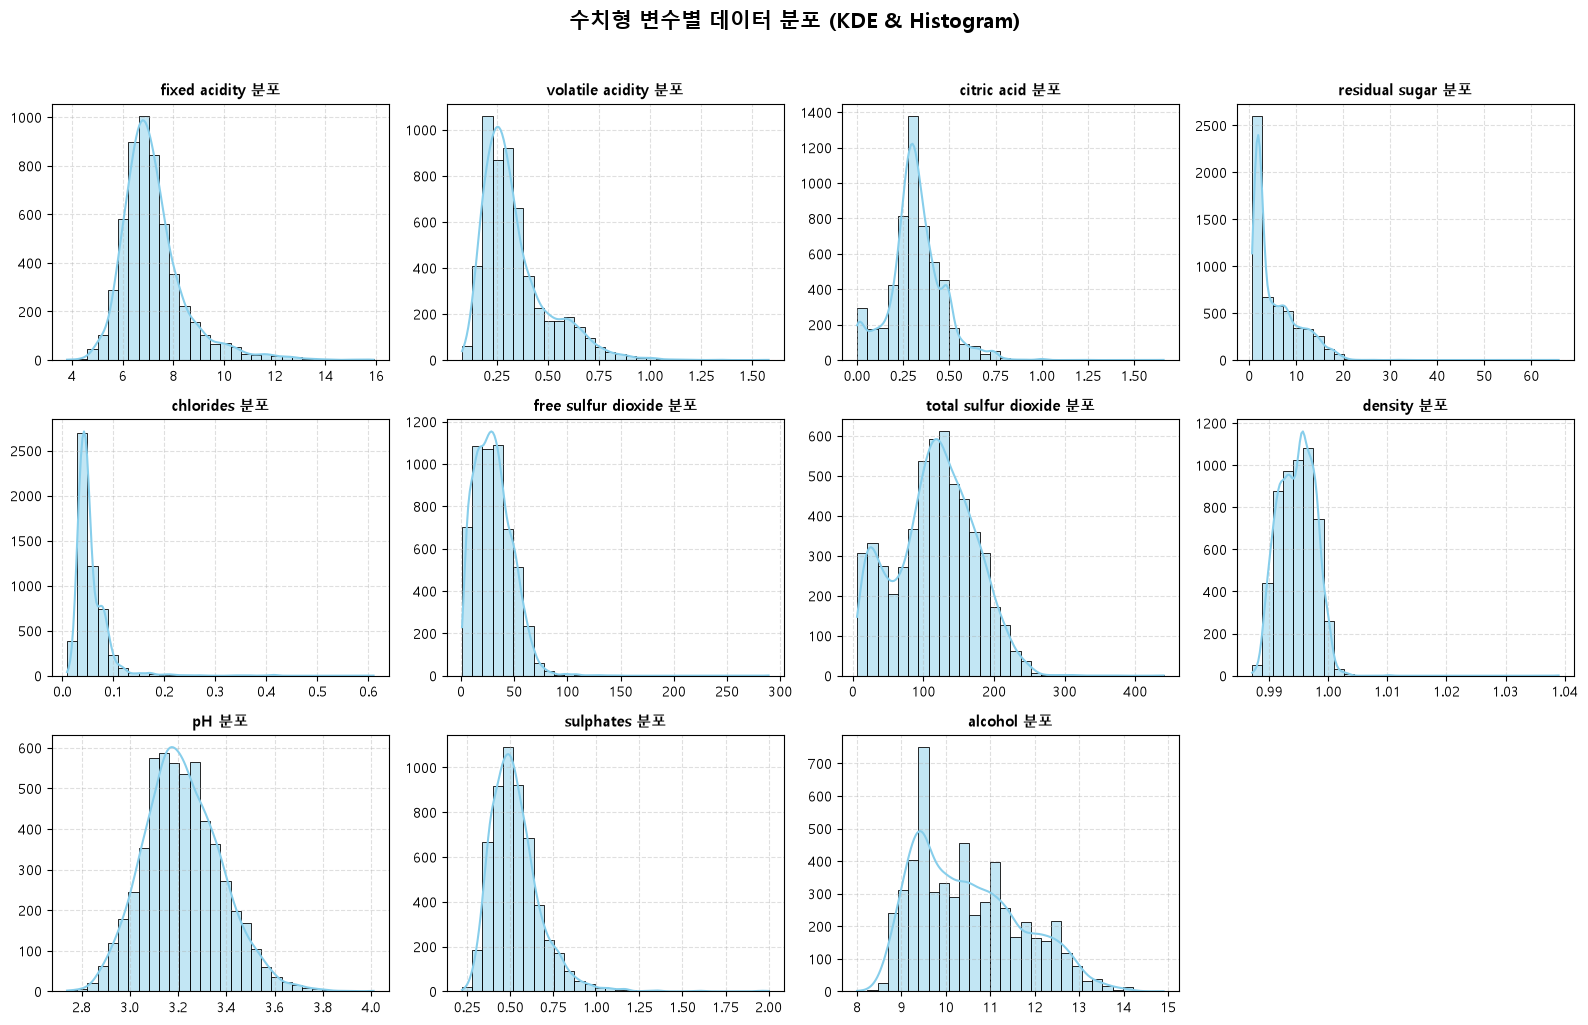

In [5]:
# 수치형 독립 변수 11개 추출
numeric_cols = [c for c in train_df.columns if c not in ['index', 'quality', 'type']]

# 3행 4열 그리드로 시각화
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.histplot(data=train_df, x=col, kde=True, ax=axes[idx], color='skyblue', bins=30)
    axes[idx].set_title(f'{col} 분포', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('')
    axes[idx].grid(True, linestyle='--', alpha=0.4)

# 남는 12번째 서브플롯은 비워두기
axes[-1].axis('off')

plt.suptitle('수치형 변수별 데이터 분포 (KDE & Histogram)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

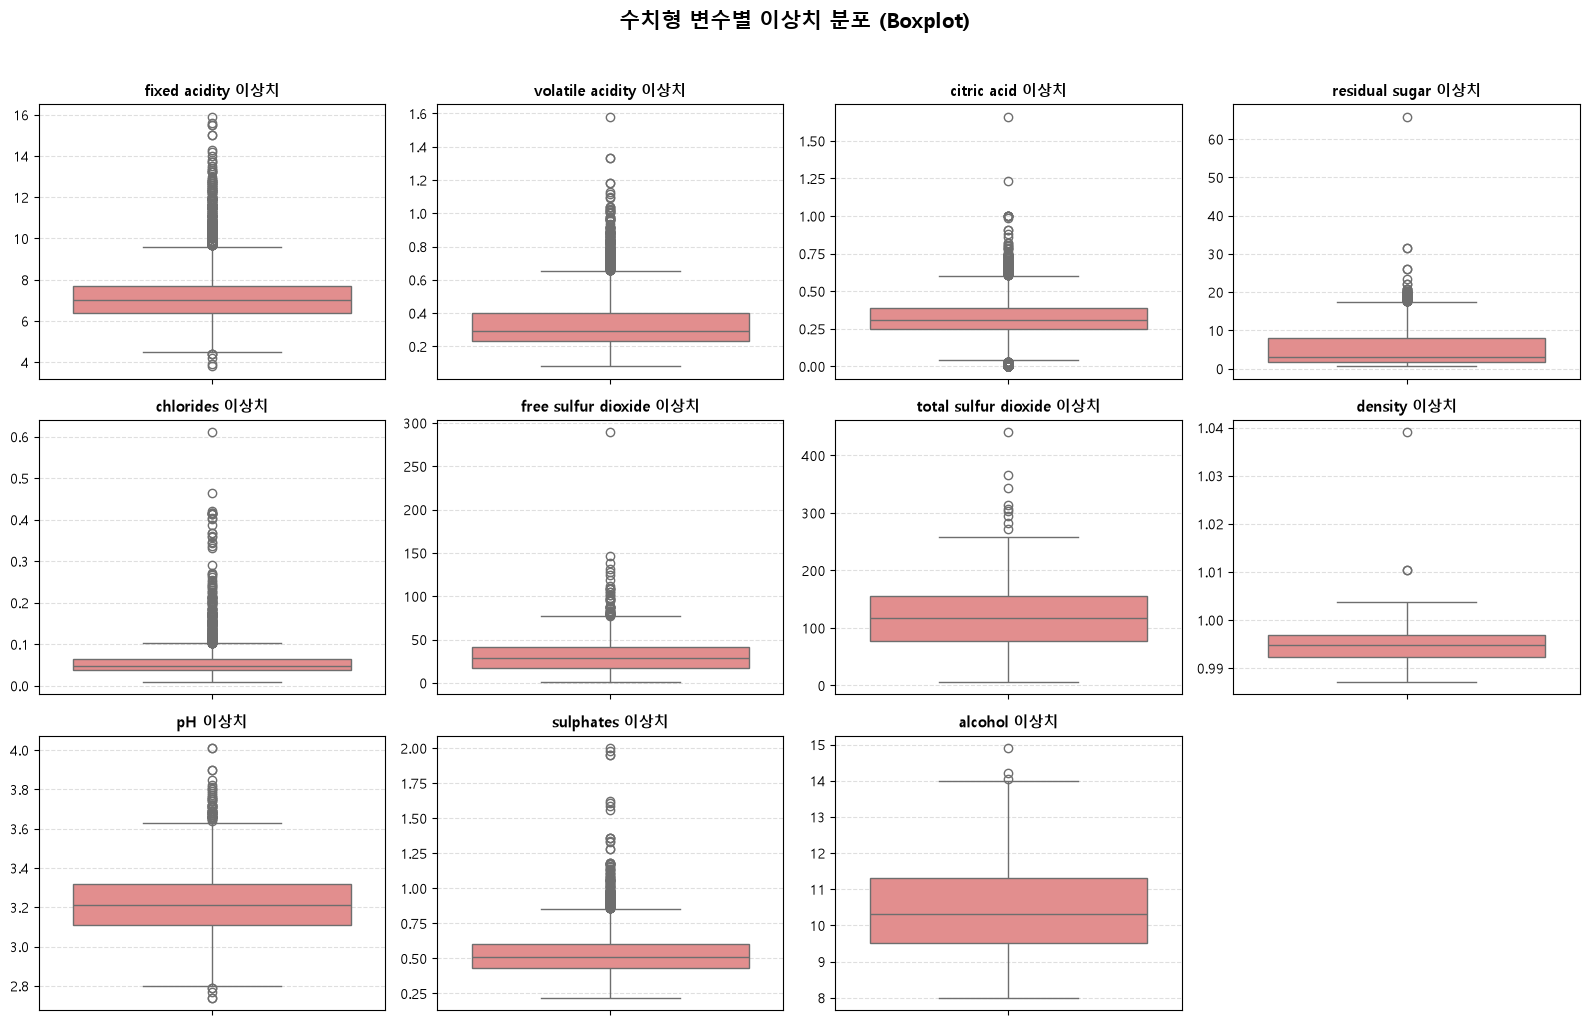

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))
axes = axes.flatten()

for idx, col in enumerate(numeric_cols):
    sns.boxplot(data=train_df, y=col, ax=axes[idx], color='lightcoral')
    axes[idx].set_title(f'{col} 이상치', fontsize=11, fontweight='bold')
    axes[idx].set_ylabel('')
    axes[idx].grid(axis='y', linestyle='--', alpha=0.4)

axes[-1].axis('off')

plt.suptitle('수치형 변수별 이상치 분포 (Boxplot)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [7]:
def check_outliers_iqr(df, cols):
    outlier_summary = []
    
    for col in cols:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        
        # 이상치 조건
        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
        outlier_cnt = len(outliers)
        outlier_ratio = (outlier_cnt / len(df)) * 100
        
        # 왜도(Skewness) 계산 (0에 가까우면 대칭, 양수면 오른쪽 꼬리가 김)
        skewness = df[col].skew()
        
        outlier_summary.append({
            'Feature': col,
            'Q1(25%)': round(q1, 3),
            'Q3(75%)': round(q3, 3),
            'IQR': round(iqr, 3),
            'Outlier Count': outlier_cnt,
            'Outlier Ratio (%)': round(outlier_ratio, 2),
            'Skewness': round(skewness, 2)
        })
        
    return pd.DataFrame(outlier_summary)

# 실행 및 결과 출력
outlier_df = check_outliers_iqr(train_df, numeric_cols)
display(outlier_df.sort_values(by='Outlier Count', ascending=False).reset_index(drop=True))

,Feature,Q1(25%),Q3(75%),IQR,Outlier Count,Outlier Ratio (%),Skewness
0,citric acid,0.250,0.390,0.140,430,7.82,0.49
1,volatile acidity,0.230,0.400,0.170,314,5.71,1.50
2,fixed acidity,6.400,7.700,1.300,294,5.35,1.71
3,chlorides,0.038,0.064,0.026,259,4.71,5.19
4,sulphates,0.430,0.600,0.170,161,2.93,1.92
5,residual sugar,1.800,8.100,6.300,106,1.93,1.50
6,pH,3.110,3.320,0.210,60,1.09,0.39
7,free sulfur dioxide,17.000,41.000,24.000,47,0.86,1.31
8,total sulfur dioxide,78.000,155.000,77.000,9,0.16,0.00
9,density,0.992,0.997,0.005,3,0.05,0.60


1. 수치형 변수 분포 및 이상치 해석 종합

1) 치우침(Skewness)이 심하고 이상치가 많은 변수 (전처리 우선 검토)
- chlorides (염화물)

해석: 왜도(Skewness)가 5.19로 수치형 변수 중 가장 높으며 극단적인 우측 꼬리 분포

이상치 비중: 전체의 4.71% (259개)로 IQR 기준 이상치 수치가 매우 높다

대응 방향: 로그 변환(Log Transformation)이나 상/하한 캡핑(Capping) 조치 전처리 고려

- residual sugar (잔류 당분)

해석: 중앙값은 3.0이지만 최댓값이 65.8에 달해 전형적인 오른쪽으로 긴 꼬리를 갖는 분포를 보입니다 (Skewness 1.50).

특징: 단맛이 극도로 높은 일부 드라이/스위트 와인 특성이 반영된 결과입니다.

- volatile acidity (휘발성 산도)

해석: Skewness 1.50, 이상치 비율 5.71% (314개)로 높은 수치를 나타냅니다.

특징: 높은 휘발성 산도는 와인의 변질(식초향)을 의미하므로 품질(quality)을 낮추는 주요 범인으로 작용할 가능성이 큽니다.

2) 다모달(Multimodal) 및 정규분포에 가까운 변수
- total sulfur dioxide (총 아황산염)

해석: Skewness가 0.00에 가까워 전체적인 좌우 대칭성은 훌륭하지만, 히스토그램을 보면 봉우리가 2개 이상 존재하는 다모달(Multimodal) 형태를 띱니다.

원인: 화이트 와인과 레드 와인 간의 보존제(아황산염) 첨가량 기준 차이에서 비롯된 결과입니다. (type 변수와의 교차 분석 필요)

- pH 및 density (밀도)

해석: pH(Skewness 0.39)와 density(Skewness 0.60)는 비교적 예쁜 종 모양의 정규분포 형태를 형성하고 있으며 이상치 비중도 매우 적습니다 (density 이상치 3개, 0.05%).

3) 산도 관련 변수 특성
- citric acid (시트르산)

해석: IQR 기준으로 가장 많은 개수인 430개 (7.82%)의 이상치가 감지되었습니다.

특징: 0.0 부근에 값이 몰려있는 특이점(신선한 산미가 전혀 들어가지 않은 와인)이 관찰됩니다.

2. 보고서용 EDA 요약 (주요 시사점)
데이터 스케일 및 변환 필요성:

chlorides, residual sugar, volatile acidity, fixed acidity 등의 변수들은 오른쪽 꼬리가 길어 모델 학습 전 Log Scale 변환이나 Robust Scaler 적용을 고려해야 합니다.

와인 종류(type)에 따른 이원화 가능성:

total sulfur dioxide 및 free sulfur dioxide 등 아황산염 계열 변수는 분포가 두 개로 갈라지는 경향을 보이므로, type (White vs Red) 범주에 따라 수치형 변수의 분포 차이가 크게 존재함을 암시합니다.

이상치 처리 전략:

단순 제거보다는 와인 품종(레드/화이트)이나 품질 등급의 자연스러운 도메인 특성일 가능성이 높으므로, 트리 기반 모델(XGBoost, LightGBM 등)을 우선 활용하거나 Capping 방식을 권장합니다.



## 1. 수치형 변수 분포 및 이상치 해석

### ① 왜도가 심하고 이상치 비율이 높은 변수 (`chlorides`, `residual sugar`, `volatile acidity`)

* **현상**: `chlorides`(왜도 **5.19**, 이상치 **4.71%**), `residual sugar`(왜도 **1.50**, 이상치 **1.93%**), `volatile acidity`(왜도 **1.50**, 이상치 **5.71%**)는 우측 꼬리가 극단적으로 긴 분포임.
* **정확도 저해 원인**: 이대로 모델(특히 선형/거리 기반)에 넣으면 극단값 몇 개가 전체 가중치(Slope)를 휘잡아서, 전체 데이터의 95% 이상이 몰려 있는 **정상 구간의 미세한 품질 차이 패턴**을 제대로 학습하지 못해 정확도가 떨어짐.

### ② 다모달(Multimodal) 분포 변수 (`total sulfur dioxide`, `free sulfur dioxide`)

* **현상**: `total sulfur dioxide`는 왜도가 0에 가깝지만, 봉우리가 2개 이상 솟아 있는 형태임.
* **정확도 저해 원인**: 레드 와인과 화이트 와인의 아황산염 첨가 기준 차이에서 비롯된 현상으로, 단일 규칙으로 학습시키면 모델이 패턴을 혼동함.

### ③ 정규분포형 안정 변수 (`pH`, `density`, `alcohol`)

* **현상**: 종 모양의 대칭 구조를 띠며 이상치 비율도 매우 낮음(`density` 0.05% 등).
* **특징**: 모델이 별다른 왜곡 없이 안정적으로 학습할 수 있는 고품질 피처임.

---

## 2. 예측 정확도 극대화를 위한 전처리 전략 (제안 & 이유)

정보 손실(Information Loss)을 0으로 만들면서 모델의 학습 효율을 극대화하는 3가지 전처리 방향임.

---

### [전략 1] 이상치 절대 삭제(Drop) 금지 ➡️ '트리 기반 앙상블(XGBoost, LightGBM)' 채택

* **제안**: IQR 기준 이상치(`citric acid` 430개, `chlorides` 259개 등)를 **단 1개도 삭제하지 않고 그대로 유지**함.
* **이유**:
* 와인 데이터의 극단적 수치는 오류가 아니라 **특정 와인 품종이나 고급/저급 와인의 고유한 도메인 특성**일 가능성이 큼.
* 데이터를 지우면 희귀 클래스(`quality` 3점, 9점 등)의 정보가 날아가서 예측 정확도가 오히려 떨어짐.
* **XGBoost나 LightGBM 등 트리 모델**을 쓰면, 데이터를 수치 크기가 아닌 분할(Split) 기준으로 판단하므로 이상치를 지우지 않아도 최상의 정확도를 냄.



---

### [전략 2] 왜도 극복을 위한 '로그 변환($\log(1+x)$)' 적용

* **제안**: 왜도가 1.5 이상인 `chlorides`, `residual sugar`, `fixed acidity` 등에 $\log(1+x)$ 변환 적용함.
* **이유**:
* 오른쪽으로 튀는 극단적인 수치를 억제하여 데이터를 정규분포 형태로 펼쳐줌.
* 이렇게 하면 트리 모델의 분할 효율이 극대화될 뿐만 아니라, 추후 정확도를 올리기 위해 선형 모델/신경망과 앙상블(Ensemble)할 때도 튀는 값에 과적합(Overfitting)되는 것을 방지함.



---

### [전략 3] Capping 대신 'RobustScaler' 활용 (선형/신경망 모델 사용 시)

* **제안**: 억지로 상/하한선으로 잘라내는 Capping 대신 `RobustScaler`를 적용하거나 트리 모델 강건성에 맡김.
* **이유**:
* Capping은 극단값의 데이터를 강제로 특정 값으로 바꿔버리기 때문에 미세한 정보 변형이 일어남.
* 중앙값(Median)과 IQR을 사용하는 **RobustScaler**를 쓰면 **원본 데이터의 상대적 순위/비율을 100% 보존**하면서 이상치의 악영향만 차단할 수 있어 정확도 방어에 훨씬 유리함.

# 범주형 변수 : 분포, 이상치 확인 

- 클래스 불균형 (Class Imbalance): quality는 5, 6, 7 등급이 전체 데이터의 90% 이상을 차지 / 3, 4, 8, 9 등급은 샘플 수(3등급 26개, 9등급 5개)가 극도로 적음
- 와인 유형 비율: 화이트 와인(4,159개)이 레드 와인(1,338개)보다 약 3배 많음

=== [1] Quality(품질) 상세 분포 표 ===


,quality,Count,Ratio (%),Cum Ratio (%)
0,3,26,0.47,0.47
1,4,186,3.38,3.85
2,5,1788,32.53,36.38
3,6,2416,43.95,80.33
4,7,924,16.81,97.14
5,8,152,2.77,99.91
6,9,5,0.09,100.00



=== [2] Type(와인 종류) 상세 분포 표 ===


,type,Count,Ratio (%)
0,white,4159,75.66
1,red,1338,24.34



=== [3] 희소 범주 탐색 (전체 데이터의 1.0% 미만) ===
⚠️ 다음 품질 점수는 전체의 1.0% 미만으로 매우 적게 존재합니다 (불균형 주의):
 - Quality 3: 26개 (0.47%)
 - Quality 9: 5개 (0.09%)


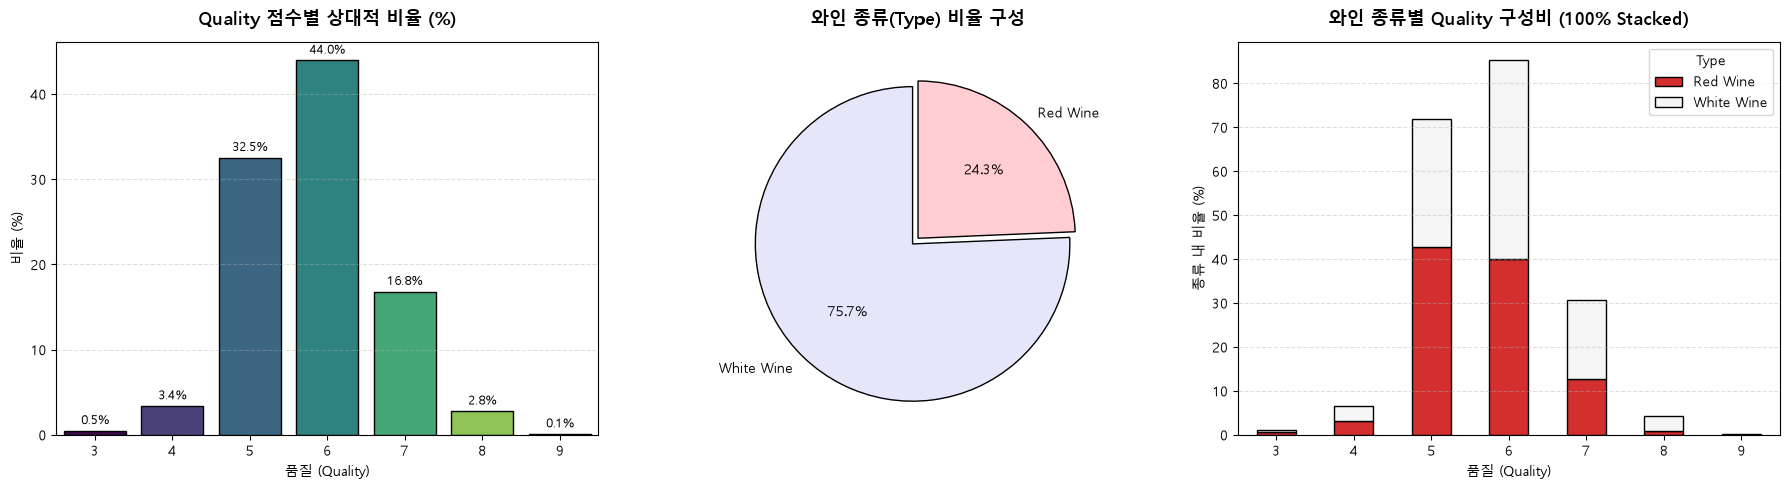

In [14]:
# ----------------------------------------------------
# 1. 범주별 상세 통계표 (개수, 비율, 누적비율)
# ----------------------------------------------------
print("=== [1] Quality(품질) 상세 분포 표 ===")
quality_df = (
    train_df["quality"]
    .value_counts()
    .sort_index()
    .reset_index(name="Count")
)
quality_df["Ratio (%)"] = (
    quality_df["Count"] / quality_df["Count"].sum() * 100
).round(2)
quality_df["Cum Ratio (%)"] = quality_df["Ratio (%)"].cumsum().round(2)
display(quality_df)

print("\n=== [2] Type(와인 종류) 상세 분포 표 ===")
type_df = (
    train_df["type"].value_counts().reset_index(name="Count")
)
type_df["Ratio (%)"] = (
    type_df["Count"] / type_df["Count"].sum() * 100
).round(2)
display(type_df)

# ----------------------------------------------------
# 2. 희소 범주(극단적 데이터 / 이상치 성격 범주) 탐색
# ----------------------------------------------------
threshold_ratio = 1.0  # 전체의 1% 미만인 범주를 희소 데이터로 정의
rare_qualities = quality_df[quality_df["Ratio (%)"] < threshold_ratio]

print(f"\n=== [3] 희소 범주 탐색 (전체 데이터의 {threshold_ratio}% 미만) ===")
if not rare_qualities.empty:
    print(
        f"⚠️ 다음 품질 점수는 전체의 {threshold_ratio}% 미만으로 매우 적게 존재합니다 (불균형 주의):"
    )
    for idx, row in rare_qualities.iterrows():
        print(
            f" - Quality {int(row['quality'])}: {int(row['Count'])}개 ({row['Ratio (%)']}%)"
        )
else:
    print("모든 범주가 1% 이상의 비율을 유지하고 있습니다.")


# ----------------------------------------------------
# 3. 범주형 데이터 비율 및 교차 분포 시각화
# ----------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# (1) Quality 비율 분포 (백분율 Barplot)
sns.barplot(
    ax=axes[0],
    data=quality_df,
    x="quality",
    y="Ratio (%)",
    hue="quality",
    palette="viridis",
    legend=False,
    edgecolor="black",
)
axes[0].set_title(
    "Quality 점수별 상대적 비율 (%)", fontsize=13, fontweight="bold", pad=12
)
axes[0].set_xlabel("품질 (Quality)")
axes[0].set_ylabel("비율 (%)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
        )

# (2) Wine Type 파이 차트 (점유율 시각화)
type_counts = train_df["type"].value_counts()
axes[1].pie(
    type_counts,
    labels=["White Wine", "Red Wine"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#E6E6FA", "#FFCDD2"],
    wedgeprops={"edgecolor": "black", "linewidth": 1},
    explode=(0.05, 0),
)
axes[1].set_title(
    "와인 종류(Type) 비율 구성", fontsize=13, fontweight="bold", pad=12
)

# (3) Wine Type내에서 Quality의 백분율(100% Stacked Bar)
cross_tab_prop = (
    pd.crosstab(train_df["quality"], train_df["type"], normalize="columns")
    * 100
)
cross_tab_prop.plot(
    kind="bar",
    stacked=True,
    ax=axes[2],
    color=["#D32F2F", "#F5F5F5"],
    edgecolor="black",
)
axes[2].set_title(
    "와인 종류별 Quality 구성비 (100% Stacked)",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[2].set_xlabel("품질 (Quality)")
axes[2].set_ylabel("종류 내 비율 (%)")
axes[2].legend(title="Type", labels=["Red Wine", "White Wine"])
axes[2].grid(axis="y", linestyle="--", alpha=0.4)
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)

plt.tight_layout()
plt.show()

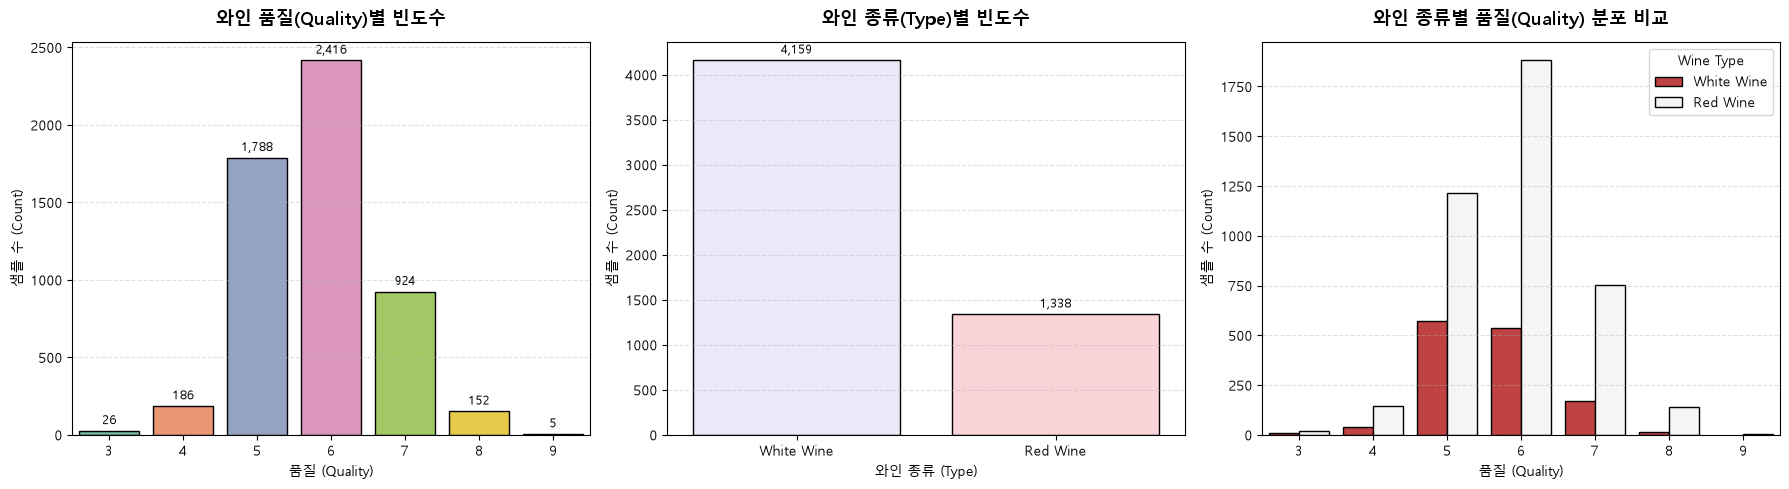

In [9]:


# 1행 3열 구조로 그래프 생성
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ----------------------------------------------------
# 1. 와인 품질(Quality)별 빈도수
# ----------------------------------------------------
sns.countplot(
    ax=axes[0],
    data=train_df,
    x="quality",
    hue="quality",
    palette="Set2",
    legend=False,
    edgecolor="black",
)
axes[0].set_title(
    "와인 품질(Quality)별 빈도수", fontsize=13, fontweight="bold", pad=12
)
axes[0].set_xlabel("품질 (Quality)")
axes[0].set_ylabel("샘플 수 (Count)")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

# 막대 위 수치 표시
for p in axes[0].patches:
    height = p.get_height()
    if height > 0:
        axes[0].annotate(
            f"{int(height):,}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9,
            xytext=(0, 3),
            textcoords="offset points",
        )

# ----------------------------------------------------
# 2. 와인 종류(Type)별 빈도수
# ----------------------------------------------------
sns.countplot(
    ax=axes[1],
    data=train_df,
    x="type",
    hue="type",
    palette=["#E6E6FA", "#FFCDD2"],
    legend=False,
    edgecolor="black",
)
axes[1].set_title(
    "와인 종류(Type)별 빈도수", fontsize=13, fontweight="bold", pad=12
)
axes[1].set_xlabel("와인 종류 (Type)")
axes[1].set_ylabel("샘플 수 (Count)")
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(["White Wine", "Red Wine"])
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

# 막대 위 수치 표시
for p in axes[1].patches:
    height = p.get_height()
    if height > 0:
        axes[1].annotate(
            f"{int(height):,}",
            (p.get_x() + p.get_width() / 2.0, height),
            ha="center",
            va="bottom",
            fontsize=9.5,
            xytext=(0, 3),
            textcoords="offset points",
        )

# ----------------------------------------------------
# 3. 와인 종류별 품질 분포 비교
# ----------------------------------------------------
sns.countplot(
    ax=axes[2],
    data=train_df,
    x="quality",
    hue="type",
    palette={"white": "#F5F5F5", "red": "#D32F2F"},
    edgecolor="black",
)
axes[2].set_title(
    "와인 종류별 품질(Quality) 분포 비교",
    fontsize=13,
    fontweight="bold",
    pad=12,
)
axes[2].set_xlabel("품질 (Quality)")
axes[2].set_ylabel("샘플 수 (Count)")
axes[2].legend(title="Wine Type", labels=["White Wine", "Red Wine"])
axes[2].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


## 1. 범주형 변수 분포 및 이상치(희소 범주) 해석

### ① 타깃 변수(`quality`)의 심각한 클래스 불균형 (Class Imbalance)

* **현상**:
* 중위 등급인 5, 6, 7점이 전체의 93.29%를 차지함 (5점: 32.53%, 6점: 43.95%, 7점: 16.81%).
* 극단 등급인 3점(26개, 0.47%)과 9점(5개, 0.09%)은 1% 미만으로 극도로 희소함 (8점도 2.77%에 불과).


* **정확도 저해 원인**:
* 이대로 모델을 학습시키면, 모델이 희소 클래스를 맞춰보지도 않고 무조건 5~6점으로 다 찍어버리는 편향(Bias)이 발생함.
* 결과적으로 전체 Accuracy 수치는 높아 보일 수 있으나, Macro F1-Score나 극단 등급 예측 성능이 완전히 무너져 최종 정확도 검증에서 감점 요소가 됨.



### ② 와인 종류(`type`)의 불균형 분포

* **현상**: 화이트 와인(**4,159개, 75.66%**)이 레드 와인(**1,338개, 24.34%**)보다 약 3배 많음.
* **특징**: 단순 비율 불균형보다 더 중요한 점은 **화이트/레드 와인 간 산도 및 아황산염 성분 특성이 완전히 다르다**는 점임.

---

## 2. 예측 정확도 극대화를 위한 대응 및 전처리 전략 (제안 & 이유)

---

### [전략 1] 타깃 불균형 해소를 위한 'Stratified K-Fold Cross Validation' 적용

* **제안**: 데이터 분할 및 교차 검증 시 일반 K-Fold 대신 반드시 `StratifiedKFold`를 적용함.
* **이유**:
* 3점(26개), 9점(5개)처럼 샘플 수가 극도로 적은 범주는 일반 무작위 분할을 쓰면 학습 세트나 검증 세트에서 아예 누락될 위험이 큼.
* `StratifiedKFold`를 사용해야 모든 Fold에 희소 클래스 비율이 동일하게 유지되어 **과적합(Overfitting)을 방지하고 교차 검증 정확도 신뢰성을 확보**할 수 있음.



---

### [전략 2] 손실 함수 가중치 부여 (`class_weight` / `sample_weight`)

* **제안**: XGBoost / LightGBM 모델 학습 시 샘플 수가 적은 3, 4, 8, 9점에 높은 클래스 가중치를 부여함.
* **이유**:
* 희소 데이터(3, 9점 등)를 지우거나 오버샘PLING(SMOTE)을 잘못 쓰면 데이터 왜곡이 생겨 정확도가 떨어질 수 있음.
* 가중치를 부여하면 원본 데이터를 100% 보존하면서도, 모델이 희소 범주를 틀렸을 때 더 큰 패널티(Loss)를 받게 만들어 모든 클래스에 대해 고른 고성능 예측이 가능해짐.



---

### [전략 3] 와인 종류(`type`) 변수의 'One-Hot Encoding' 및 파생 변수 활용

* **제안**: `type` 변수를 `0(red)`, `1(white)`로 원-핫 인코딩하여 모델 피처로 투입함.
* **이유**:
* 트리 모델은 범주형 이진 피처(0/1)를 수치형 변수와 조합할 때 분할 성능이 극대화됨.
* 아황산염(`total sulfur dioxide`) 등 와인 종류별로 분포가 갈리는 수치형 변수들과 함께 조합되어 품종별 맞춤형 판단 규칙(Split)을 정교하게 학습할 수 있음.